# 1. What is in the experiment, and can we use it?

The goal is to understand the source data before interpreting treatment effects. Every record is synthetic. We inspect missingness, case mix, skew, repeat contacts and survey coverage. The experiment plan is stored separately; this EDA does not change its decision thresholds.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import polars as pl
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
ROOT = Path.cwd()
if not (ROOT / 'config').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src'))
from support_policy.common import config
mart = pl.read_parquet(ROOT / 'data/marts/experiment_mart.parquet')
plt.rcParams.update({'figure.figsize': (9, 4), 'axes.spines.top': False, 'axes.spines.right': False})
pl.Config.set_tbl_rows(20)
print(f'{mart.height:,} customers; synthetic data only')


100,000 customers; synthetic data only


## Source inventory and analytical grain
Six source tables feed one customer-level mart. Event rows must never become the experiment sample size.

In [2]:
inventory=[]
for path in sorted((ROOT/'data/raw').glob('*.parquet')):
    f=pl.read_parquet(path)
    inventory.append({'table':path.stem,'rows':f.height,'columns':f.width})
display(pl.DataFrame(inventory))
assert mart['customer_id'].n_unique()==mart.height
print('One row per customer:', mart.height)


One row per customer: 100000


table,rows,columns
str,i64,i64
"""assignments""",100000,4
"""case_events""",226549,4
"""customers""",100000,6
"""refund_transactions""",61843,4
"""satisfaction_responses""",47032,4
"""support_cases""",113968,5


## Required fields and missing outcomes
An unresolved case contributes 168 hours. Missing satisfaction stays missing. Replacing it with zero would mix nonresponse with a bad rating.

In [3]:
display(mart.null_count().unpivot(variable_name='field',value_name='nulls').filter(pl.col('nulls')>0))
validation=json.loads((ROOT/'outputs/validation_report.json').read_text())
print('Source checks passed:',sum(validation['checks'].values()),'of',len(validation['checks']))
assert validation['passed']
display(mart.group_by('policy').agg(pl.len().alias('customers'),
    (1-pl.col('resolved_7d').mean()).alias('unresolved_rate'),
    pl.col('survey_responded').mean().alias('response_rate')).sort('policy'))


Source checks passed: 27 of 27


field,nulls
str,u32
"""csat""",52968


policy,customers,unresolved_rate,response_rate
str,u32,f64,f64
"""Current policy""",50180,0.074472,0.492148
"""Simplified policy""",49820,0.060458,0.448334


## Case mix
Issue category is known before assignment. The simulation makes duplicate-charge cases more complex; that is an input assumption, not a discovered fact about real customers.

In [4]:
mix=mart.group_by('issue_type','policy').agg(pl.len().alias('customers'),
    pl.col('prior_contacts_30d').mean().alias('prior_contacts_mean'),
    pl.col('tenure_days').median().alias('median_tenure_days')).sort('issue_type','policy')
display(mix)
region=mart.group_by('region','policy').agg(pl.len().alias('customers')).sort('region','policy')
display(region)


issue_type,policy,customers,prior_contacts_mean,median_tenure_days
str,str,u32,f64,f64
"""Cancellation refund""","""Current policy""",12594,0.694378,743.5
"""Cancellation refund""","""Simplified policy""",12377,0.694514,757.0
"""Duplicate charge""","""Current policy""",15074,0.691854,753.0
"""Duplicate charge""","""Simplified policy""",14933,0.712784,742.0
"""Fare adjustment""","""Current policy""",22512,0.701892,750.0
"""Fare adjustment""","""Simplified policy""",22510,0.701821,754.0


region,policy,customers
str,str,u32
"""Region A""","""Current policy""",25064
"""Region A""","""Simplified policy""",24883
"""Region B""","""Current policy""",15145
"""Region B""","""Simplified policy""",15104
"""Region C""","""Current policy""",9971
"""Region C""","""Simplified policy""",9833


## Enrolment over time
Large allocation changes by day would prompt a logging or randomisation investigation. The overall allocation check appears in Notebook 2.

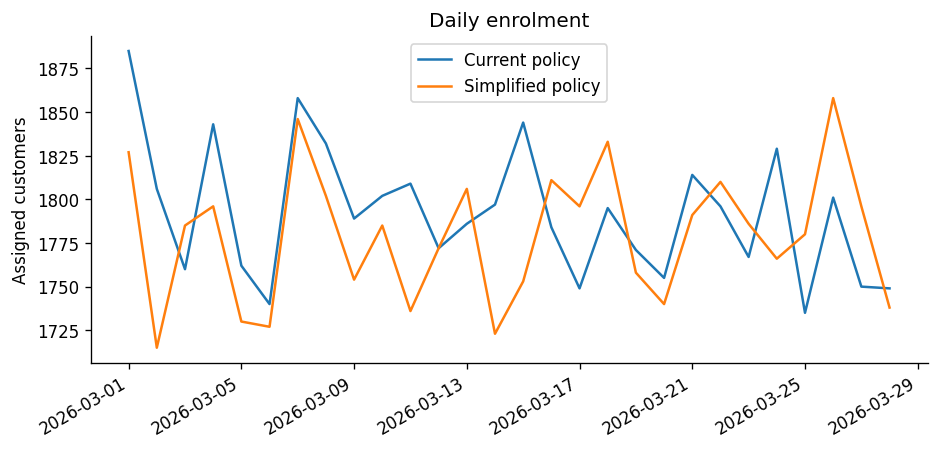

In [5]:
daily=pl.read_parquet(ROOT/'data/marts/daily_enrolment.parquet')
fig,ax=plt.subplots()
for label in sorted(daily['policy'].unique().to_list()):
    d=daily.filter(pl.col('policy')==label).sort('assignment_date')
    ax.plot(d['assignment_date'].to_list(),d['customers'].to_list(),label=label)
ax.set(ylabel='Assigned customers',title='Daily enrolment');ax.legend();fig.autofmt_xdate();plt.show()


## Waiting-time distribution
The mean alone hides the right tail and the mass at the cap. The primary endpoint includes that cap rather than excluding unresolved customers.

policy,mean_hours,median_hours,p90_hours,p95_hours
str,f64,f64,f64,f64
"""Current policy""",44.518952,27.318889,119.606389,168.0
"""Simplified policy""",39.286769,22.632083,101.536667,168.0


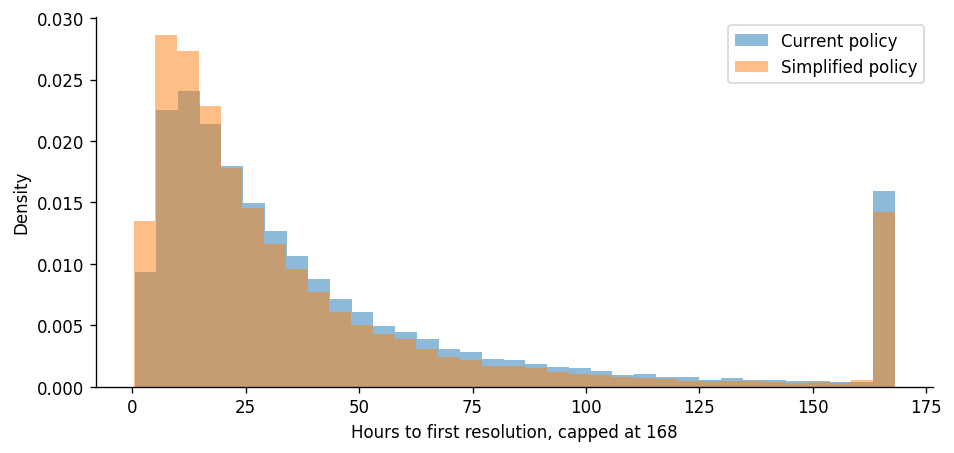

In [6]:
display(mart.group_by('policy').agg(
    pl.col('unresolved_hours_7d').mean().alias('mean_hours'),
    pl.col('unresolved_hours_7d').median().alias('median_hours'),
    pl.col('unresolved_hours_7d').quantile(.90).alias('p90_hours'),
    pl.col('unresolved_hours_7d').quantile(.95).alias('p95_hours')))
fig,ax=plt.subplots()
for label in sorted(mart['policy'].unique().to_list()):
    x=mart.filter(pl.col('policy')==label)['unresolved_hours_7d'].to_numpy()
    ax.hist(x,bins=35,alpha=.5,density=True,label=label)
ax.set(xlabel='Hours to first resolution, capped at 168',ylabel='Density');ax.legend();plt.show()


## Contacts outside the follow-up window
The raw source deliberately includes late contacts. They should not enter seven-day outcomes.

In [7]:
cases=pl.read_parquet(ROOT/'data/raw/support_cases.parquet')
linked=cases.join(mart.select('customer_id','assigned_at','window_end'),on='customer_id').filter(~pl.col('is_index'))
display(linked.select(pl.len().alias('all_repeat_cases'),
    (pl.col('opened_at')<=pl.col('window_end')).sum().alias('within_seven_days'),
    (pl.col('opened_at')>pl.col('window_end')).sum().alias('after_seven_days')))
assert mart['repeat_count_7d'].sum()==linked.filter((pl.col('opened_at')>pl.col('assigned_at'))&(pl.col('opened_at')<=pl.col('window_end'))).height


all_repeat_cases,within_seven_days,after_seven_days
u32,u32,u32
13968,11002,2966


## Refund distribution and denominator
Spend is calculated per assigned customer, including zero-refund cases. Comparing only paid customers would change the population after treatment.

In [8]:
display(mart.group_by('policy').agg(pl.col('refund_usd_7d').mean().alias('mean_per_assigned_customer'),
    (pl.col('refund_usd_7d')==0).mean().alias('zero_refund_share'),
    pl.col('refund_usd_7d').quantile(.99).alias('p99_refund_usd')))


policy,mean_per_assigned_customer,zero_refund_share,p99_refund_usd
str,f64,f64,f64
"""Simplified policy""",4.125754,0.379285,18.99
"""Current policy""",3.690014,0.383838,18.42


## Survey selection
Check who replied before interpreting the rating. A policy can change both the experience and the chance that a customer responds.

In [9]:
display(mart.group_by('policy','repeat_contact_7d').agg(pl.len().alias('customers'),
    pl.col('survey_responded').mean().alias('response_rate'),pl.col('csat').mean().alias('respondent_score')).sort('policy','repeat_contact_7d'))


policy,repeat_contact_7d,customers,response_rate,respondent_score
str,i32,u32,f64,f64
"""Current policy""",0,45151,0.500786,4.05431
"""Current policy""",1,5029,0.414595,3.455635
"""Simplified policy""",0,43847,0.458184,3.969338
"""Simplified policy""",1,5973,0.376025,3.365539


## What this EDA establishes
The mart has the right grain, complete follow-up and explicit outcome denominators. The wait distribution is skewed and satisfaction is incomplete. Those observations explain the capped primary endpoint and separate response-rate reporting. Causal estimates and uncertainty come next; descriptive group differences alone are not the rollout decision.